# Week 10 · Session 1 — From a cube in memory to a clean time series
## Storing the Saldaña cube in HDF5 and preparing its NDVI time series

**Geoprocesamiento · Maestría en Geomática · Universidad Nacional de Colombia**

In Week 8 we built the Sentinel-2 NDVI cube of the Saldaña rice district (the reference cube **E3**: offset corrected, clouds masked, one layer per day). But it lived only in the memory of the notebook: when the session closed, it disappeared, and with it every decision we took. Today we do two things:

| Part | Question | What you will do | Time |
|---|---|---|---|
| **A** | How do we **keep** a cube, with its decisions? | Rebuild cube E3 and store it in an HDF5 file designed for reading **time series** | ≈ 60 min |
| **B** | How do we turn **irregular, gappy** observations into a series we can analyse? | Remove dips, regularise to half-months, fill short gaps and smooth | ≈ 75 min |

At the end you will have **two files**: the observed cube (`saldana_ndvi_cube.h5`) and a regular, gap-filled, smoothed cube (`saldana_ndvi_semimonthly.h5`). Sessions 2 and 3 (trends, anomalies, phenology) start from them.

### A new habit: functions in a `.py` file
Today the functions do **not** live in the notebook. They live in a separate file, **`ts_tools.py`** (our *toolbox*), and the notebook **imports** them. The notebook stays short and tells the story; the `.py` file keeps the details, well commented, ready to be reused in other notebooks — including your final project.

## 0 · Setup

| Library | Why we need it today |
|---|---|
| `numpy`, `pandas` | arrays (the cube) and tables (the time series) |
| `matplotlib` | figures |
| `pystac-client`, `planetary-computer`, `odc-stac` | search and load Sentinel-2 (Part A, as in Week 8) |
| `h5py` | write and read HDF5 files (as in Week 7) |
| `scipy` | the Savitzky–Golay smoothing filter (Part B) |

**Why this cell?** If you work on Google Colab or in a new environment, some of these libraries are missing. Remove the `#` at the start of the `%pip` line, run the cell **once**, and then restart the kernel (*Kernel → Restart*). If your environment already has them, skip this cell.

In [ ]:
# Run ONLY if the libraries are missing (Colab or a new environment). Remove the '#' below, run once, restart.
# %pip install -q pystac-client planetary-computer odc-stac xarray dask h5py scipy matplotlib pandas

### 0.1 Our toolbox: what is a module?

A **module** is simply a `.py` file full of functions. To use it from a notebook:

1. **The file must be in the same folder as the notebook** (download `ts_tools.py` together with this notebook; on Colab, upload both).
2. We write `import ts_tools as tt`. From then on, every function of the file is available as `tt.name_of_the_function(...)`. The short name `tt` is our choice, like `np` for numpy.

**Why this cell?** Besides importing the toolbox, it switches on **autoreload**. Without it, Python reads `ts_tools.py` only once: if you later edit the file (you will, in a challenge), the notebook would keep using the old version. With `%autoreload 2`, every time you run a cell Python checks whether the file changed and reloads it.

In [1]:
# %load_ext autoreload: switches on a Jupyter extension called "autoreload".
#   The % sign marks a "magic command": an instruction for Jupyter, not for Python .
%load_ext autoreload

# %autoreload 2: before running each cell, check whether any imported module
#   has changed on disk and, if so, load it again. The number is the mode:
#   0 = off, 1 = only modules marked with %aimport, 2 = all imported modules.
# Why we need it: Python reads a module only once, at the first import.
#   Without autoreload, if you edit src/ts_tools.py (challenge B.4), the notebook
#   keeps using the old version until you restart the kernel.
%autoreload 2
# go into the folder src and load the file ts_tools.py.
from src import ts_tools as tt


**Why this cell?** Every function in `ts_tools.py` has a *docstring*: a description of what it does, of **each argument** and of what it returns. `help(...)` prints it. Use it whenever you are not sure how to call a function. Let us read the function that merges the two copies of the same day (Week 8, Section 2.4).

In [2]:
help(tt.fuse_same_day)

Help on function fuse_same_day in module src.ts_tools:

fuse_same_day(values, times)
    Merge the layers that belong to the same day into ONE layer.
    
    Rule: for each pixel, keep the FIRST valid (not NaN) value among the
    layers of that day, in time order. Apply the cloud mask BEFORE this
    function, so that a cloudy copy is skipped and a clear copy is kept.
    
    Parameters
    ----------
    values : numpy array, shape (time, y, x)
        The layers (for example NDVI), already masked (clouds = NaN).
    times : list or pandas.DatetimeIndex, length = number of layers
        Acquisition time of each layer, in time order.
    
    Returns
    -------
    fused : numpy array, shape (days, y, x)
        One layer per day.
    days : pandas.DatetimeIndex
        The day of each fused layer.
    n_layers : numpy array, shape (days,)
        How many layers were merged into each day (1 or 2 in Saldaña).



> 💡 **Clarification — how to read a function in the `.py` file.** Open `ts_tools.py` (double-click it in Jupyter, or in any text editor). Every function looks like this:
>
> ```python
> def compute_ndvi(red, nir):          # "def" + name + (arguments)
>     """What it does, each argument,   # the docstring: read by help()
>     and what it returns."""
>     ...                               # the work, with a comment on every important line
>     return ndvi                       # what comes back to the notebook
> ```
>

### 0.2 Settings of the session

import the general libraries and write in **one place** every value we may want to change later: the area, the period, the CRS and the names of the files we will create. If you move to another area, this is the only cell to edit.

In [3]:
import time                          # to measure how long things take
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)   # e.g. "All-NaN slice": expected in cloudy pixels

# rasterio briefly creates a temporary in-memory image without georeferencing
# while it reprojects; with parallel loading (A2), its own silencing of that warning
# can fail and "NotGeoreferencedWarning" appears. The result IS correctly
# georeferenced (we check it in A4), so we hide this one warning only.
from rasterio.errors import NotGeoreferencedWarning
warnings.filterwarnings("ignore", category=NotGeoreferencedWarning)


warnings.filterwarnings("ignore", category=RuntimeWarning)   # e.g. "All-NaN slice": expected in cloudy pixels

# Default style for ALL the figures of this notebook (set once, used everywhere):
#   figure.dpi = 110 -> figures shown a little larger and sharper (default 100)
#   axes.grid = True -> a background grid in every plot, to read NDVI values
#   grid.alpha = 0.3 -> a soft, semi-transparent grid (0 = invisible, 1 = solid)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# --- Area and period: the same as in Week 8 ------------------------------------
CENTRE_LAT, CENTRE_LON = 3.915, -74.985          # centre of the window (degrees, WGS 84)
HALF_SIZE_DEG = 0.0163                           # ≈ 1.8 km  ->  window of ≈ 3.6 x 3.6 km
BBOX = [CENTRE_LON - HALF_SIZE_DEG, CENTRE_LAT - HALF_SIZE_DEG,   # west, south,
        CENTRE_LON + HALF_SIZE_DEG, CENTRE_LAT + HALF_SIZE_DEG]   # east, north
PERIOD = "2021-07-01/2022-06-30"                 # one year that crosses the 2022 offset
CRS = "EPSG:32618"                               # UTM zone 18 North (metres)

# --- Files we will create -------------------------------------------------------
CUBE_FILE = "saldana_ndvi_cube.h5"               # Part A: observed cube (irregular dates)
MAPS_FILE = "saldana_ndvi_cube_mapchunks.h5"     # Part A: same data, chunks for maps (experiment)
REGULAR_FILE = "saldana_ndvi_semimonthly.h5"     # Part B: regular, gap-filled, smoothed cube

print("bbox:", np.round(BBOX, 4), "| period:", PERIOD)

bbox: [-75.0013   3.8987 -74.9687   3.9313] | period: 2021-07-01/2022-06-30


# Part A · Keeping the cube: from memory to an HDF5 file

### Why store the cube?
* **It survives.** A cube in memory disappears when the kernel stops. Rebuilding it means searching and downloading again (minutes, and the catalogue may have changed).
* **It keeps the decisions.** Week 8 showed that the cube *is* its decisions: offset, mask, duplicate rule, grid. A good file writes them inside, so anyone (you, in six months) can understand and reproduce it **without this notebook**.
* **It can be read fast — if it is designed for the way we will read it.** Today we will read **time series** (all the dates of one pixel), so we design the chunks for that.

### The recipe of cube E3 (Week 8)

| Decision | What we do | Where in `ts_tools.py` |
|---|---|---|
| Grid | UTM 18 N, 10 m (native grid of B04 and B08, no interpolation) | `load_raw_cube` |
| Duplicates | load one layer per item, merge the copies of each day **after** masking | `load_raw_cube`, `fuse_same_day` |
| Radiometry | reflectance = DN / 10 000 + offset, offset = −0.1 if baseline ≥ 04.00 | `offsets_for_layers`, `to_reflectance` |
| Mask | keep SCL classes 4, 5, 6 (vegetation, bare, water) | `clear_mask` |
| Index | NDVI = (NIR − red) / (NIR + red) | `compute_ndvi` |

### A1 · Search the catalogue

aSK Planetary Computer for the Sentinel-2 L2A images over our window and period (`tt.search_sentinel2`), and builds a table with their metadata (`tt.items_table`): time, tile, processing baseline and cloud cover.

The table tells us how many images we have, whether the window falls on two tiles (duplicates) and which images carry the 2022 offset. Nothing is downloaded yet, only metadata.

In [4]:
items = tt.search_sentinel2(BBOX, PERIOD, max_cloud=80)
table = tt.items_table(items)

# How many images (items) did the search find? -number of rows of the table.
print(len(table), "items")

# How many images come from each Sentinel-2 tile?
#   table["tile"]   -> takes the column "tile" (e.g. 18NVK, 18NWK)
#   .value_counts() -> counts how many times each different value appears
#   .to_dict()      -> turns the result into a dictionary {tile: count}, easier to read
#   If there are TWO tiles, many dates are duplicated: the same day appears twice.
print("items per tile:", table["tile"].value_counts().to_dict())

# How many images were processed with each processing baseline?
#   Same idea as above, with the column "baseline".
#   .sort_index() orders the result by baseline (e.g. 3.0 before 4.0).
#   Images with baseline >= 4.0 carry the +1000 DN offset (from 25 January 2022).
print("items per baseline:", table["baseline"].value_counts().sort_index().to_dict())

# How many DIFFERENT days have at least one image?
#   .nunique() = number of unique (different) values in the column "date".
#   If this number is smaller than the number of items, some days have two images they will be fused into one layer later.
print("distinct dates:", table["date"].nunique())

# Show the first 5 rows of the table, to see what each column contains.
#   We do not use print() here: as the LAST line of a cell.
table.head()

97 items
items per tile: {'18NVK': 50, '18NWK': 47}
items per baseline: {3.0: 55, 4.0: 31, 5.1: 11}
distinct dates: 45


,id,time,tile,baseline,cloud,date
0,S2A_MSIL2A_20210702T152641_R025_T18NVK_2021070...,2021-07-02 15:26:41.024,18NVK,3.0,31.001236,2021-07-02
1,S2A_MSIL2A_20210702T152641_R025_T18NWK_2021070...,2021-07-02 15:26:41.024,18NWK,3.0,51.933531,2021-07-02
2,S2B_MSIL2A_20210707T152639_R025_T18NVK_2021070...,2021-07-07 15:26:39.024,18NVK,3.0,36.404365,2021-07-07
3,S2B_MSIL2A_20210707T152639_R025_T18NWK_2021070...,2021-07-07 15:26:39.024,18NWK,3.0,48.498698,2021-07-07
4,S2A_MSIL2A_20210712T152641_R025_T18NVK_2021071...,2021-07-12 15:26:41.024,18NVK,3.0,57.163245,2021-07-12


### A2 · Load the pixels: a raw cube (one layer per item)

Read the red (B04), near-infrared (B08) and SCL bands of every item over our window, on a 10 m UTM grid, with **one layer per item** (`tt.load_raw_cube`).

**This is already a cube, but a raw one.** `raw` has dimensions (time, y, x), coordinates (dates and pixel centres in metres) and variables (B04, B08, SCL) on one regular grid. But it is not yet the cube we will analyse: a cube is **built in stages**, and in A3 we apply the four decisions of cube E3 to it.

| | `raw` (A2) | `cube` (A3) |
|---|---|---|
| Values | raw digital numbers | reflectance, with the 2022 offset corrected |
| Variable | B04, B08, SCL | NDVI |
| Clouds | still there | masked (NaN) |
| Layers | one per **image** (days repeated by the two tiles) | one per **day** |

**Why one layer per item?** Our window lies where two Sentinel-2 tiles overlap, so most days appear **twice** (one copy per tile). The final cube must have **one layer per day**, so we must decide which value to keep in each pixel: our **rule for duplicates**. If the library merged the two copies now, it would keep the first value with data, even if it is a cloud. Loading each copy separately lets us **mask the clouds of each copy first** and then keep, per pixel, the first **clear** value of the day (Week 8, Section 2.4).

⏳ This is the slowest step: between one and four minutes, depending on the connection. 

In [5]:
# Start a stopwatch: time.perf_counter() gives the current time in seconds.
#   We save it in t0 to measure how long the loading takes.
t0 = time.perf_counter()

# Download the bands and put them on a common grid (where do you think you can find the function?):
#   items        - the images found in A1
#   BBOX         - the area of study (longitude/latitude), defined in the settings
#   crs=CRS      - the coordinate system of the cube (UTM 18 N, EPSG:32618)
#   resolution=10 - pixel size in metres
#   The result "raw" holds the bands B04 (red), B08 (near infrared) and SCL
#   (scene classification), with ONE layer per image: duplicates are not fused yet.
raw = tt.load_raw_cube(items, BBOX, crs=CRS, resolution=10)

# How long did it take? Current time minus the start time = seconds elapsed.
#   f"..." is an f-string: the expression inside { } is replaced by its value.
#   :.0f means "show it as a number with 0 decimals".
print(f"Loaded in {time.perf_counter() - t0:.0f} s")

# Size of each dimension of the raw cube:
#   time = number of layers (one per image, so it should equal the number of items in A1)
#   y, x = number of pixel rows and columns of the area
#   dict(...) turns the sizes into a dictionary, easier to read.
print("dimensions:", dict(raw.sizes))

Loaded in 63 s
dimensions: {'y': 361, 'x': 363, 'time': 97}


### A3 · Apply the decisions of cube E3

**What this cell does.** `tt.build_ndvi_cube` applies, in this order: sort the layers by time → digital numbers to reflectance **with the offset of each layer** → NDVI → cloud mask (clouds become `NaN`) → one layer per day. It returns a **dictionary** (a box with labelled compartments):

| Key | Content |
|---|---|
| `cube["ndvi"]` | numpy array (days, rows, columns) with NDVI; `NaN` = no clear observation |
| `cube["time"]` | the day of each layer |
| `cube["x"]`, `cube["y"]` | coordinates of the pixel centres (metres, UTM) |
| `cube["provenance"]` | a table with one row per day: how many layers were merged, which tiles, which baseline and offset, which fraction of the window is clear |

**Why we need it.** From here on we work with the **clean** cube. The provenance table travels with it, so every value can be traced back to its images.

In [6]:
# Build the clean NDVI cube by applying the four decisions of cube E3, in this order:
#   1) sort the layers by date
#   2) DN -> reflectance, subtracting the offset (-0.1) when the baseline is >= 04.00
#   3) NDVI, and NaN where SCL is not 4, 5 or 6 (clouds, shadows...)
#   4) fuse the images of the same day (the two tiles) into ONE layer
# Inputs:
#   raw   = the raw cube from A2 (B04, B08, SCL; one layer per image)
#   table = the table from A1 (we need the baseline of each image for the offset)
# The result is a DICTIONARY with five parts:
#   cube["ndvi"]       -> the cube (days, rows, columns); NaN = no clear observation
#   cube["time"]       -> the dates, one per layer
#   cube["x"], cube["y"] -> coordinates of the pixel centres, in metres (UTM)
#   cube["provenance"] -> the history of each day (see the last line)
cube = tt.build_ndvi_cube(raw, table)# Do not forget to check the function

# .shape gives the size of the NDVI array along each dimension: (days, rows, columns).
#   We "unpack" the three numbers into three variables in one line.
#   Check: n_days should equal "distinct dates" in A1 (smaller than the number of
#   items, because the duplicates of the two tiles were fused).
n_days, ny, nx = cube["ndvi"].shape
print(f"NDVI cube: {n_days} days x {ny} rows x {nx} columns")

# .nbytes = memory used by the array, in bytes. Dividing by 1e6  gives megabytes.
#   :.0f shows the number without decimals.
print(f"memory: {cube['ndvi'].nbytes / 1e6:.0f} MB")

# Provenance = WHERE EACH LAYER COMES FROM. One row per day of the cube:
#   date           = the day; row k describes layer k of cube["ndvi"]
#   n_layers       = how many images were fused that day (2 = both tiles)
#   tiles          = which tiles they came from
#   baseline       = ESA processing version of the images
#   offset         = correction applied to the reflectance (0 or -0.1)
#   clear_fraction = fraction of the area with a clear observation that day
#                    (0.15 = only 15 % of the pixels have a value; the rest are clouds)
# If a value looks strange later, this table tells us what happened that day.

cube["provenance"].head()

NDVI cube: 45 days x 361 rows x 363 columns
memory: 24 MB


,date,n_layers,tiles,baseline,offset,clear_fraction
0,2021-07-02,2,"18NVK,18NWK",3.0,0.0,0.877323
1,2021-07-07,2,"18NVK,18NWK",3.0,0.0,0.875400
2,2021-07-12,2,"18NVK,18NWK",3.0,0.0,0.863861
3,2021-07-22,1,18NWK,3.0,0.0,0.000000
4,2021-07-27,2,"18NVK,18NWK",3.0,0.0,0.071427


> ✏️ **Your turn — read the function.** Open `src/ts_tools.py` and find `build_ndvi_cube`. It calls other small functions of the same file: find them too. Answer **in your own words**, in a markdown cell below:
>
> 1. **Order.** Which lines sort the layers by date? Why do we need `order` (and not just `times.sort()`) to keep B04, B08 and SCL aligned?
>2. **Offset.** Which function decides the offset of each layer? It needs the baseline of each image: is that information in `raw` (the pixels from A2) or in `table` (the catalogue metadata from A1)? How does the function connect a layer of `raw` with its row in `table`?> 3. **Reflectance.** In `to_reflectance`, what happens to a pixel whose digital number is 0? Why?
> 4. **Mask.** Which line puts NaN where the pixel is not clear? Which SCL classes are kept, and where is that list defined?
> 5. **Duplicates.** In `fuse_same_day`, when a day has two layers, which value is kept in each pixel?
> 6. **What if…?** The mask (step 3) is applied **before** the fusion (step 4). What would go wrong if we swapped those two lines? Use a pixel that is cloudy in one tile and clear in the other.
> 7. **Provenance.** How is `clear_fraction` computed? Is it the cloud cover of the whole Sentinel-2 tile, or of our window?

### A4 · Look before you save

The following cell does two quick checks: (left) the NDVI map of the clearest day, and (right) the fraction of the window that is clear on each day.

 Saving a broken cube only makes the error permanent. The map should show paddies (green or brown blocks), canals and the river; the right panel shows how irregular and cloudy our time axis is — the problem Part B will deal with.

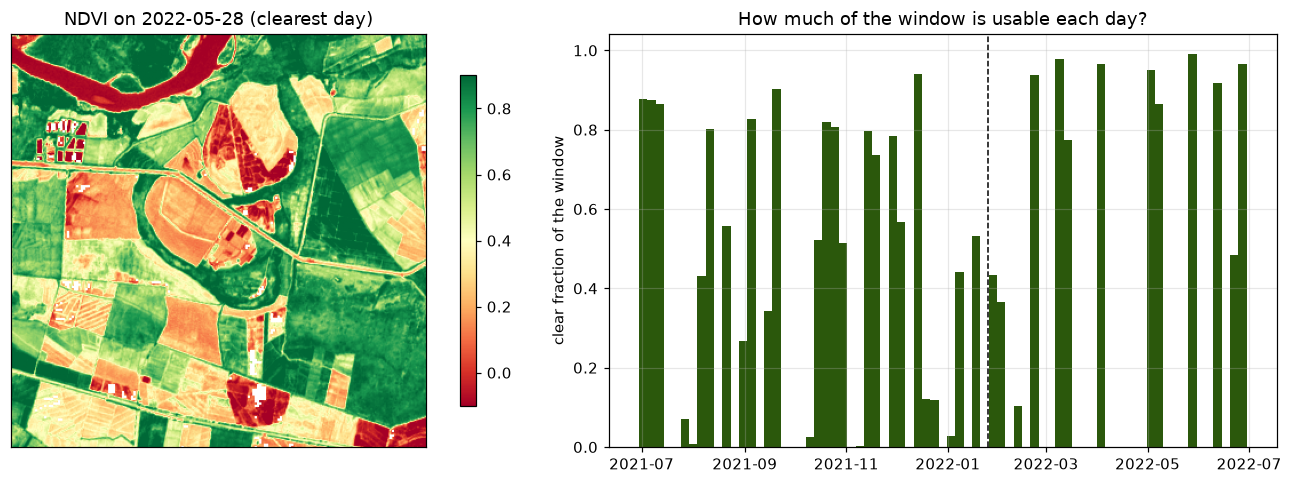

In [7]:
# Short name for the provenance table (one row per day of the cube).
prov = cube["provenance"]

# Find the clearest day: the row with the highest clear_fraction.
#   .idxmax() gives the POSITION (row number) of the maximum value.
#   int(...) turns it into a plain integer, to use it as an index of the cube.
#   Row k of the provenance table describes layer k of cube["ndvi"].
k_best = int(prov["clear_fraction"].idxmax())

# A figure with two panels side by side: axes[0] (left) and axes[1] (right).
#   figsize = (width, height) in inches.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# --- Left panel: the NDVI map of the clearest day ------------------------------
#   cube["ndvi"][k_best] = the layer of that day (rows x columns).
#   imshow draws a 2-D array as an image.
#   cmap="RdYlGn"   -> colour scale red (low NDVI) - yellow - green (high NDVI).
#   vmin, vmax      -> the NDVI values for the two ends of the colour scale,
#                      so that maps of different days use the same colours.
im = axes[0].imshow(cube["ndvi"][k_best], cmap="RdYlGn", vmin=-0.1, vmax=0.9)
axes[0].set_title(f"NDVI on {prov['date'][k_best]} (clearest day)")
axes[0].set_xticks([]); axes[0].set_yticks([])     # hide the axis numbers (pixel indices)
plt.colorbar(im, ax=axes[0], shrink=0.8)           # colour legend; shrink = 80 % of the panel height

# --- Right panel: how clear was the window each day? ----------------------------
#   One bar per day of the cube: its height is the fraction of pixels with a clear
#   observation (1 = whole window clear, 0 = all clouds).
#   pd.to_datetime turns the date texts into real dates, so the x axis is a time axis.
#   width=5 -> each bar is 5 days wide (images arrive about every 5 days).
axes[1].bar(pd.to_datetime(prov["date"]), prov["clear_fraction"], width=5, color="#2B580C")

# Dashed vertical line on 25 January 2022: from this day on, images carry the
#   +1000 offset (baseline 04.00). Useful to check that nothing strange happens there.
axes[1].axvline(tt.OFFSET_DATE, color="k", ls="--", lw=1)
axes[1].set_ylabel("clear fraction of the window")
axes[1].set_title("How much of the window is usable each day?")

# tight_layout adjusts the spacing so titles and labels do not overlap; show the figure.
plt.tight_layout(); plt.show()

### A5 · Design the file: which chunk shape?

Recall what we learnt on our last sessions: an HDF5 dataset is cut into chunks, and a chunk is always read whole. So the chunk shape decides how much must be read for each question.

**Two ways of cutting the same cube.** Imagine the cube as a pile of maps, one map per date, stacked in time:

| | **Map-friendly**: chunks of (1, rows, columns) | **Series-friendly**: chunks of (48, 40, 40) |
|---|---|---|
| How the cube is cut | in **horizontal slices**: each chunk is **one whole map** (one date, all the pixels) | in **vertical columns**: each chunk is a **small square of 40 × 40 pixels with all its dates** |
| Like… | the pages of a book | cores drilled through the whole pile |
| One chunk contains | 1 date × all rows × all columns | 48 dates × 40 × 40 pixels |

```
   Map-friendly                     Series-friendly
   (one chunk = one map)            (one chunk = 40 x 40 pixels, all dates)

   date 46  ┌──────────────┐        ┌───┬───┬───┬───┐
     ...    ├──────────────┤        │   │   │   │   │
   date 2   ├──────────────┤        │ ▓ │   │   │   │  ← one chunk goes through
   date 1   └──────────────┘        └───┴───┴───┴───┘     ALL the dates
```
> ⚠️ The names only say **which question each design is good for**. With **either** design we can ask **both** questions: the data are the same, only the **cost** changes.
Each design is fast for one question and slow for the other:

* **Question 1: "all the dates of one pixel"** (a time series). Map-friendly: the pixel is in **every** map, so we must read **all the maps** (46 chunks) to get one number from each. Series-friendly: the pixel and all its dates are in **one** core, so we read **1 chunk** (as long as the cube has 48 dates or fewer).
* **Question 2: "one date for the whole area"** (a map). Map-friendly: that map is **one** chunk. Series-friendly: the map is spread over **all** the cores (9 × 9 = 81 chunks), and each of them holds 48 dates: to read one map we read practically **the whole cube**.

Our file will look like this:
```
saldana_ndvi_cube.h5
├── (global attributes)   title, CRS, grid, and the decisions of E3 (offset, mask, duplicates)
├── x        (columns)              pixel-centre eastings, metres
├── y        (rows)                 pixel-centre northings, metres
├── time     (days)                 days since 1970-01-01   ← can grow
├── ndvi     (days, rows, columns)  float32, chunks (48, 40, 40), gzip + shuffle   ← can grow
└── provenance/   date, n_layers, tiles, baseline, offset, clear_fraction   (one value per day)
```

**Why chunks of (48, 40, 40)?** Our main question today is *"give me all the dates of this pixel"*. With 48 dates per chunk (about a year of Sentinel-2 days), **one chunk contains the whole series** of 40 × 40 = 1 600 pixels. Size of one chunk: 48 × 40 × 40 × 4 bytes (float32) ≈ 307 kB — inside the 10 kB – 1 MB range recommended for HDF5.

> 💡 NDVI is stored as **float32**: a decimal number that uses **32 bits** (a bit is a single 0 or 1). Since **1 byte = 8 bits**, one float32 value takes 32 ÷ 8 = 4 bytes. The 32 bits follow the international standard IEEE 754: 1 bit for the sign, 8 for the scale (exponent) and 23 for the digits, which gives about 7 significant digits. That is far more than NDVI needs (its measurement error is around 0.01), so float32 is enough. A float64 would take 8 bytes per value and make the file and every chunk twice as large.
>
> So the size of one chunk is simply *number of values × bytes per value*: 48 × 40 × 40 = 76 800 values × 4 bytes = **307 200 bytes ≈ 307 kB** (uncompressed; on disk it is smaller thanks to gzip).


In the next cell, before saving the file, we **predict** how much work two typical questions will cost:

* **Question 1:** "give me all the dates of **one pixel**" (a time series);
* **Question 2:** "give me **one date** for the whole area" (a map).

We count **how many chunks** each question has to read, using `tt.chunks_touched`. We do it for two designs:

* **our design**, chunks of (48, 40, 40), made for time series;
* **a design for maps**, chunks of (1, rows, columns): one whole date per chunk.

Fewer chunks = less to read = faster.

In [8]:
# The size of our cube: (days, rows, columns). We need it to know where the chunks fall.
shape = cube["ndvi"].shape

# The TWO DESIGNS we compare: name of the design -> its chunk shape (days, rows, columns)
designs = {"series-friendly (48, 40, 40)": (48, 40, 40),
           "map-friendly (1, rows, cols)": (1, shape[1], shape[2])}

# The pixel we ask about in Question 1. Any pixel works: the result is the same.
row, col = 100, 100

print(f"Cube: {shape[0]} days x {shape[1]} rows x {shape[2]} columns")
print("Question 1: all the dates of ONE pixel (a time series)")
print("Question 2: ONE date for the whole area (a map)")
print("A chunk is always read WHOLE -> cost = chunks touched x size of one chunk\n")

for name, chunks in designs.items():

    # QUESTION 1 · "all the dates of ONE pixel"
    #   days: 0 to shape[0] (all) | rows: row to row+1 (one) | columns: col to col+1 (one)
    n_series = tt.chunks_touched(shape, chunks, start=(0, row, col), stop=(shape[0], row + 1, col + 1))

    # QUESTION 2 · "ONE date for the whole area"
    #   days: 0 to 1 (one) | rows and columns: all
    n_map = tt.chunks_touched(shape, chunks, start=(0, 0, 0), stop=(1, shape[1], shape[2]))

    # Size of ONE chunk in kB = number of values x 4 bytes (float32) / 1 000
    chunk_kb = chunks[0] * min(chunks[1], shape[1]) * min(chunks[2], shape[2]) * 4 / 1e3

    print(f"Design: {name}  (one chunk = {chunk_kb:.0f} kB)")
    print(f"   Question 1 (one pixel, all dates): reads {n_series:3d} chunk(s) = {n_series * chunk_kb / 1e3:6.2f} MB")
    print(f"   Question 2 (one date, whole map):  reads {n_map:3d} chunk(s) = {n_map * chunk_kb / 1e3:6.2f} MB\n")

Cube: 45 days x 361 rows x 363 columns
Question 1: all the dates of ONE pixel (a time series)
Question 2: ONE date for the whole area (a map)
A chunk is always read WHOLE -> cost = chunks touched x size of one chunk

Design: series-friendly (48, 40, 40)  (one chunk = 307 kB)
   Question 1 (one pixel, all dates): reads   1 chunk(s) =   0.31 MB
   Question 2 (one date, whole map):  reads 100 chunk(s) =  30.72 MB

Design: map-friendly (1, rows, cols)  (one chunk = 524 kB)
   Question 1 (one pixel, all dates): reads  45 chunk(s) =  23.59 MB
   Question 2 (one date, whole map):  reads   1 chunk(s) =   0.52 MB



🤔 **Reflect — The series-friendly design reads one chunk for a pixel series but 81 chunks for a map. Is that a bad design?**

<details><summary>Show a model answer (try first!)</summary>

Not for today's work. A chunk shape is always a compromise for a workload: we will read hundreds of pixel series (Part B, and the trend and phenology analyses of the next sessions) and only a few maps. If the main use were maps (for example, a web viewer showing one date at a time), the map-friendly design would be better. There is no best chunk shape in general, only a best shape for a way of reading.

</details>

### A6 · Write the cube to HDF5

**What this cell does.** It writes the file with `tt.save_cube_hdf5`. Look at the function in `ts_tools.py`: it creates the coordinates, the time axis as *days since 1970-01-01* (CF convention, Week 7), the `ndvi` dataset (chunked, compressed, extendible in time) and the `provenance` group.

**Why the `attrs` dictionary?** These are the **global attributes**: short texts stored inside the file that record the decisions. Without them, the file contains numbers; with them, it contains an explanation.

In [9]:
# The GLOBAL ATTRIBUTES of the file: the general rules of the cube, written INSIDE it.
# They are the "convention + provenance" metadata of the theory: anyone who opens the
# file can know how the cube was made, without this notebook. It is a dictionary:
# name of the attribute -> its value (short texts or numbers).
attrs = {
    # --- the grid ---
    "crs": CRS,                                   # coordinate system: UTM 18 N (EPSG:32618)
    "resolution_m": 10.0,                         # pixel size, in metres
    "coordinates_note": "x, y are pixel CENTRES", # x, y give the centre of each pixel, not its corner
    # --- what and where ---
    "aoi_bbox_lonlat": np.array(BBOX),            # area of study: west, south, east, north (degrees)
    "period": PERIOD,                             # dates searched in the catalogue
    "source": "Sentinel-2 L2A, Microsoft Planetary Computer STAC (collection sentinel-2-l2a)",
    # --- the decisions of cube E3 (the "recipe") ---
    "offset_rule": "reflectance = DN/10000 + offset; offset = -0.1 if processing baseline >= 04.00 (per layer)",
    "clear_classes": "SCL in (4, 5, 6): vegetation, not vegetated, water",          # cloud mask
    "duplicate_rule": "mask first, then per pixel the first valid value among the layers of the same UTC day",
}
# Note: what changes DATE BY DATE (layers fused, tiles, baseline, offset, clear fraction)
# is not here: it goes in the "provenance" group, one value per day (see A3).

# Write the HDF5 file (see the function in src/ts_tools.py, PART 3). It stores:
#   the NDVI cube, cut into chunks of (48, 40, 40) as designed in A5 and compressed
#   (gzip + shuffle); the coordinates x, y and time; the provenance table; and attrs.
tt.save_cube_hdf5(CUBE_FILE, cube, chunks=(48, 40, 40), attrs=attrs)

# Compare the size of the file on disk with the size of the NDVI in memory.
#   os.path.getsize(...) -> size of the file, in bytes;  / 1e6 -> megabytes.
#   cube['ndvi'].nbytes  -> size of the NDVI array in memory (values x 4 bytes, float32).
#   The file is smaller thanks to compression: clouds (NaN) and similar
#   neighbouring values compress very well.
import os
print(f"{CUBE_FILE}: {os.path.getsize(CUBE_FILE) / 1e6:.1f} MB on disk "
      f"(uncompressed NDVI: {cube['ndvi'].nbytes / 1e6:.1f} MB)")

saldana_ndvi_cube.h5: 10.6 MB on disk (uncompressed NDVI: 23.6 MB)


### A7 · Is the file self-describing?

**What this cell does.** `tt.describe_hdf5` walks through the file and prints every dataset (shape, type, chunks, compression) and the global attributes.

**Why we need it.** It is the test of a good file: someone who has **never seen this notebook** should understand what is inside, in which units, on which grid and with which decisions.

In [10]:
import h5py

# Open the file in read-only mode ("r"). "with" closes it automatically at the end.
with h5py.File(CUBE_FILE, "r") as f:
    print("GLOBAL ATTRIBUTES (the rules of the cube):")
    for name, value in f.attrs.items():          # every attribute: name -> value
        print(f"  {name:18s}: {value}")

    print("\nWHAT IS INSIDE:")
    for name in f:                                # every dataset or group at the top level
        print(" ", name, f[name])                 # shows its shape and type (or that it is a group)

GLOBAL ATTRIBUTES (the rules of the cube):
  aoi_bbox_lonlat   : [-75.0013   3.8987 -74.9687   3.9313]
  clear_classes     : SCL in (4, 5, 6): vegetation, not vegetated, water
  coordinates_note  : x, y are pixel CENTRES
  created           : 2026-11-10 09:59
  crs               : EPSG:32618
  duplicate_rule    : mask first, then per pixel the first valid value among the layers of the same UTC day
  offset_rule       : reflectance = DN/10000 + offset; offset = -0.1 if processing baseline >= 04.00 (per layer)
  period            : 2021-07-01/2022-06-30
  resolution_m      : 10.0
  source            : Sentinel-2 L2A, Microsoft Planetary Computer STAC (collection sentinel-2-l2a)
  title             : Sentinel-2 L2A NDVI cube (Week 8 reference cube E3)

WHAT IS INSIDE:
  ndvi <HDF5 dataset "ndvi": shape (45, 361, 363), type "<f4">
  provenance <HDF5 group "/provenance" (6 members)>
  time <HDF5 dataset "time": shape (45,), type "<f8">
  x <HDF5 dataset "x": shape (363,), type "<f8">
  y <H

In [11]:
tt.describe_hdf5(CUBE_FILE)

/
  ndvi                         shape=(45, 361, 363)   float32  chunks=(48, 40, 40)   compression=gzip
provenance/
  provenance/baseline          shape=(45,)            float64  chunks=(48,)          compression=None
  provenance/clear_fraction    shape=(45,)            float64  chunks=(48,)          compression=None
  provenance/date              shape=(45,)            |S10     chunks=(48,)          compression=None
  provenance/n_layers          shape=(45,)            int64    chunks=(48,)          compression=None
  provenance/offset            shape=(45,)            float64  chunks=(48,)          compression=None
  provenance/tiles             shape=(45,)            |S11     chunks=(48,)          compression=None
  time                         shape=(45,)            float64  chunks=(48,)          compression=None
  x                            shape=(363,)           float64  chunks=None           compression=None
  y                            shape=(361,)           float64  chunk

> ✏️ **Your turn — read directly from the file.** The cube is now saved on disk. Imagine you closed the notebook and only have the file: **do not use the variable `cube`** (that copy lives in memory and disappears when the kernel stops). Open `saldana_ndvi_cube.h5` with `h5py` and read **only** what you need:
>
> 1. **One map:** the NDVI of the clearest day (`k_best`) for the whole area. *(This is Question 2 of A5.)*
> 2. **One pixel series:** all the dates of the pixel in row 100, column 100. *(This is Question 1 of A5.)*
> 3. **The dates:** read `time` and turn the numbers into real dates. Hint: look at its `units` attribute, and use `pd.to_datetime(..., unit="D")`.
> 4. Plot the map and the series side by side.
>
> **Hints.** Open the file with `with h5py.File(CUBE_FILE, "r") as f:`. A dataset is read like a numpy array: `f["ndvi"][k]` is one layer and `f["ndvi"][:, row, col]` is one pixel through time. Only the chunks you touch are read from disk.
>
> **Think about it.** Which of the two readings is cheaper with our chunks (48, 40, 40)? Why? Check your answer against A5 and A8.

In [12]:
# Write your script here

### A8 · Experiment: does the chunk shape really change the reading time?

**What this cell does.** It writes the **same data** a second time with map-friendly chunks `(1, rows, columns)`, then reads 100 random pixel series and 10 maps from each file and measures the time.

**Why we need it.** In A5 we *predicted* with the cost model; now we *measure*. (Timings vary from computer to computer; look at the **ratio** between the two files, not at the exact seconds.)

In [13]:
tt.save_cube_hdf5(MAPS_FILE, cube, chunks=(1, ny, nx), attrs=attrs)

rng = np.random.default_rng(42)                   # random pixels, but the same ones for both files
rows = rng.integers(0, ny, 100)
cols = rng.integers(0, nx, 100)

results = []
for file_name in (CUBE_FILE, MAPS_FILE):
    t0 = time.perf_counter()
    for r, c in zip(rows, cols):
        tt.read_pixel_series(file_name, r, c)
    t_series = time.perf_counter() - t0

    t0 = time.perf_counter()
    for k in range(10):
        tt.read_map(file_name, k)
    t_maps = time.perf_counter() - t0
    results.append({"file": file_name, "100 pixel series (s)": round(t_series, 2), "10 maps (s)": round(t_maps, 2)})

pd.DataFrame(results)

,file,100 pixel series (s),10 maps (s)
0,saldana_ndvi_cube.h5,0.26,0.96
1,saldana_ndvi_cube_mapchunks.h5,7.64,0.02


🤔 **Reflect — Which file wins for each question, and does the ranking agree with the prediction of A5?**

<details><summary>Show a model answer (try first!)</summary>

The series-friendly file should read the 100 pixel series much faster (each series = 1 chunk of ≈ 300 kB instead of one chunk **per date**, i.e. dozens of whole maps), while the map-friendly file should read maps faster (1 chunk instead of 81). The exact factor depends on compression, the disk and the chunk cache, but the **ranking** follows the cost model. This is the golden rule of Week 7: *chunks follow the dominant access pattern*.

</details>

### A9 · Read the whole cube back, and check it

**What this cell does.** It reads the full cube from the file (`tt.load_cube_hdf5`) and compares it with the cube in memory: same missing values, same NDVI values, same dates.

**Why we need it.** *Trust, but verify.* A file that cannot be read back exactly is useless. From now on, Part B works **only with the file**: you could restart the kernel here and continue.

In [14]:
back = tt.load_cube_hdf5(CUBE_FILE)

same_nan = np.array_equal(np.isnan(back["ndvi"]), np.isnan(cube["ndvi"]))
same_values = np.allclose(back["ndvi"], cube["ndvi"], equal_nan=True)
same_dates = bool((back["time"] == cube["time"]).all())
print("same missing values:", same_nan, "| same NDVI:", same_values, "| same dates:", same_dates)
back["provenance"].tail()

same missing values: True | same NDVI: True | same dates: True


,baseline,clear_fraction,date,n_layers,offset,tiles
40,5.1,0.864029,2022-05-08,4,-0.1,"18NVK,18NWK"
41,5.1,0.991331,2022-05-28,2,-0.1,18NVK
42,4.0,0.917233,2022-06-12,2,-0.1,"18NVK,18NWK"
43,4.0,0.483070,2022-06-22,2,-0.1,"18NVK,18NWK"
44,4.0,0.965569,2022-06-27,2,-0.1,"18NVK,18NWK"


## ✏️ Your turn — Part A

1. **Read the provenance.** From `back["provenance"]`: how many days came from **two** tiles? How many days carry the offset −0.1? Which is the first day with offset −0.1, and does it match 25 January 2022?
2. **A balanced design.** Write the cube a third time with chunks `(16, 60, 60)`. **First predict** with `tt.chunks_touched` how many chunks a pixel series and a map need, **then measure** as in A8. Where does it sit between the two other designs?
3. **(Optional) A field instead of a pixel.** How many chunks does reading a block of 30 dates × 50 × 50 pixels need in each of the three designs?

## End of Part A

Our cube is now saved in `saldana_ndvi_cube.h5`, with its decisions inside. In **Part B** (`week10_session1_partB_timeseries.ipynb`) we will **open this file** and turn its irregular observations into a regular time series — without downloading anything again.